# Multi-Layer Perceptrons: Bending the Boundary

*Stacking neurons to solve what a single one never could.*

In [Lesson 3](03_ActivationFunctions.ipynb) we trained a single neuron —
sigmoid or ReLU, it didn't matter which — with gradient descent, and ran into
a hard ceiling. No matter how it was trained, a single neuron's decision
boundary is always **one straight line**. AND and OR sit on one side of that
ceiling (linearly separable); **XOR sits on the other side**, permanently out
of reach.

This lesson breaks the ceiling — not with a cleverer neuron, but with *more
than one*, wired together into a small network. By the end you will be able
to:

1. Describe what a **hidden layer** is, and write a network's forward pass as
   matrix arithmetic.
2. Explain why a hidden layer needs a **nonlinear** activation function to do
   anything a single layer of neurons couldn't already do.
3. **Hand-design** a 2-neuron hidden layer plus a 1-neuron output layer that
   solves XOR, by decomposing it into gates a single neuron already knows how
   to learn.
4. Visualize how the hidden layer reshapes the input space into one where the
   remaining problem *is* linearly separable.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. One neuron's ceiling, one more time

Here's the data that broke every single neuron in Lessons 2 and 3. XOR fires
when *exactly one* input is 1:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Plotted as points, the two 1s and two 0s sit at alternating corners of a
square. Every single neuron we tried — step, sigmoid, ReLU, hand-picked or
trained — draws exactly one straight line through that square, and no
straight line has both 1s on one side and both 0s on the other. That's not a
training failure; it's a ceiling on what *one* neuron's decision boundary can
even be **shaped** like.

The fix is not a better neuron. It's a **network** of them.


In [2]:
# The same 4 points and labels used throughout Lessons 2 and 3.
inputs = np.array(
    [
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1],
    ]
)

and_labels = np.array([0, 0, 0, 1])
or_labels = np.array([0, 1, 1, 1])
xor_labels = np.array([0, 1, 1, 0])

## 2. From one neuron to a network

A **multi-layer perceptron** (MLP) arranges neurons into **layers**, feeding
the *output* of one layer in as the *input* to the next:

- The **input layer** isn't made of neurons at all — it's just the raw inputs
  ($x_1, x_2$) handed to the network.
- A **hidden layer** is a layer of neurons sandwiched in between. It's called
  "hidden" because nothing in our training data ever tells it directly what
  it should output — unlike the final layer, whose output we can compare
  against a known target (like an XOR label).
- The **output layer** is the last layer, whose output is the network's
  actual prediction.

Every neuron in a layer works exactly like the single neurons from Lessons 2
and 3 — weighted sum, plus bias, through an activation function — except its
*inputs* are now the previous layer's outputs, not necessarily the raw data.
Here's the shape we'll build for XOR: 2 inputs, a hidden layer of 2 neurons,
and 1 output neuron.


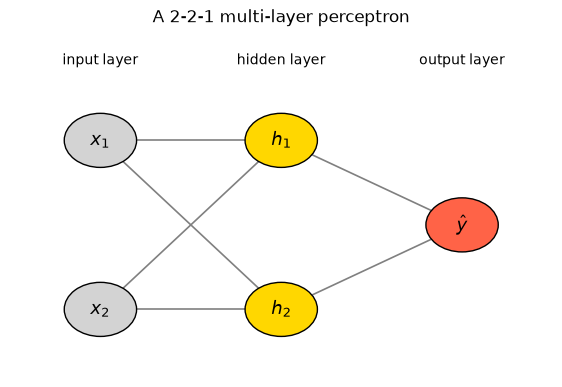

In [3]:
def draw_network_diagram():
    "Sketch the 2-input, 2-hidden-neuron, 1-output-neuron network we'll build."
    fig, ax = plt.subplots(figsize=(7, 4.5))

    layer_x = {"input": 0.0, "hidden": 1.6, "output": 3.2}
    positions = {
        "x1": (layer_x["input"], 1.0),
        "x2": (layer_x["input"], -1.0),
        "h1": (layer_x["hidden"], 1.0),
        "h2": (layer_x["hidden"], -1.0),
        "y": (layer_x["output"], 0.0),
    }
    labels = {
        "x1": "$x_1$",
        "x2": "$x_2$",
        "h1": "$h_1$",
        "h2": "$h_2$",
        "y": "$\\hat{y}$",
    }
    colors = {
        "x1": "lightgray",
        "x2": "lightgray",
        "h1": "gold",
        "h2": "gold",
        "y": "tomato",
    }

    for src in ["x1", "x2"]:
        for dst in ["h1", "h2"]:
            ax.plot(
                *zip(positions[src], positions[dst]),
                color="gray",
                zorder=1,
                linewidth=1.2,
            )
    for src in ["h1", "h2"]:
        ax.plot(*zip(positions[src], positions["y"]), color="gray", zorder=1, linewidth=1.2)

    for name, (px, py) in positions.items():
        ax.add_patch(plt.Circle((px, py), 0.32, color=colors[name], ec="black", zorder=3))
        ax.text(px, py, labels[name], ha="center", va="center", zorder=4, fontsize=13)

    ax.text(layer_x["input"], 1.9, "input layer", ha="center", fontsize=10)
    ax.text(layer_x["hidden"], 1.9, "hidden layer", ha="center", fontsize=10)
    ax.text(layer_x["output"], 1.9, "output layer", ha="center", fontsize=10)

    ax.set_xlim(-0.8, 4.0)
    ax.set_ylim(-1.8, 2.3)
    ax.axis("off")
    ax.set_title("A 2-2-1 multi-layer perceptron")
    return fig


draw_network_diagram()
plt.show()

## 3. The forward pass, in matrix form

Passing data through this network — the **forward pass** — is just two
single-neuron-layer computations from Lessons 2 and 3, back to back.

**Layer 1 (hidden):** every input row $\mathbf{x}$ feeds into *both* hidden
neurons at once. Stack each neuron's weights as a *column* of a weight
matrix $W_1$ (2 inputs $\times$ 2 hidden neurons), and their biases into a
vector $b_1$:

$$ Z_1 = X W_1 + b_1 \qquad A_1 = \text{activation}(Z_1) $$

**Layer 2 (output):** the hidden layer's outputs $A_1$ become the *input* to
the output neuron, with its own weights $W_2$ (2 hidden outputs $\times$ 1
output neuron) and bias $b_2$:

$$ Z_2 = A_1 W_2 + b_2 \qquad \hat{y} = \text{activation}(Z_2) $$

That's the whole idea: each layer is a weighted-sum-plus-bias-plus-activation
step, same as before, just chained.


In [4]:
def forward_pass(X, W1, b1, W2, b2, activation):
    "Run a batch of inputs through a 2-layer network: (hidden output, final output)."
    Z1 = X @ W1 + b1
    A1 = activation(Z1)
    Z2 = A1 @ W2 + b2
    A2 = activation(Z2)
    return A1, A2

## 4. Hand-designing XOR

In Lesson 2 we hand-picked weights for AND and OR before ever training
anything. Let's do the same trick here, using a bit of logic:

$$ \text{XOR}(x_1, x_2) = \text{OR}(x_1, x_2) \ \text{AND} \ \text{NAND}(x_1, x_2) $$

In words: XOR fires when *at least one* input is 1 (OR), **and** *not both*
are 1 (NAND — "not AND"). Check it against the truth table above and you'll
see it matches all four rows. The key point: **OR, NAND, and AND are each,
individually, linearly separable** — every one of them is learnable by a
single neuron, exactly like Lesson 2. XOR is just their *combination*.

So: build a hidden layer of two neurons — one wired as OR, one wired as
NAND — and an output neuron wired as AND that combines their two outputs.
We already know weights for all three, reusing Lesson 2's AND and OR gates
directly (NAND is just AND with everything negated):


In [5]:
# Hidden layer: column 0 computes OR, column 1 computes NAND.
# (NAND = AND with weights and bias negated, so it fires exactly when AND wouldn't.)
W1 = np.array(
    [
        [1.0, -1.0],  # weights from x1
        [1.0, -1.0],  # weights from x2
    ]
)
b1 = np.array([-0.5, 1.5])

# Output layer: AND of the two hidden outputs (h1 = OR, h2 = NAND).
W2 = np.array([[1.0], [1.0]])
b2 = np.array([-1.5])


def step(z):
    "Step activation: outputs 1 if z >= 0, otherwise 0."
    return np.where(z >= 0, 1, 0)


hidden_out, network_out = forward_pass(inputs, W1, b1, W2, b2, step)
network_out = network_out.flatten()

print(f"{'x1':>3} {'x2':>3} {'h1 (OR)':>8} {'h2 (NAND)':>10} {'output':>7} {'target':>7}")
for x, h, pred, target in zip(inputs, hidden_out, network_out, xor_labels):
    print(f"{x[0]:>3} {x[1]:>3} {h[0]:>8.0f} {h[1]:>10.0f} {pred:>7} {target:>7}")

print(f"\nAll correct: {np.all(network_out == xor_labels)}")

 x1  x2  h1 (OR)  h2 (NAND)  output  target
  0   0        0          1       0       0
  0   1        1          1       1       1
  1   0        1          1       1       1
  1   1        1          0       0       0

All correct: True


No training, no gradient descent — just wiring together three neurons
whose weights we already knew — and the network gets all four XOR cases
right. Two neurons that each draw a straight line, combined by a third,
can do something no single one of them could.


## 5. Watching the boundary bend

Let's shade the input square by the network's output, the same way Lesson 3
shaded a single neuron's decision surface — but this time running every grid
point through the full 2-layer forward pass.


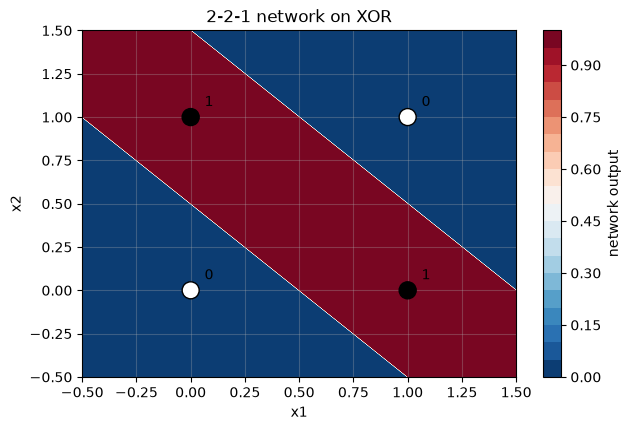

In [6]:
def plot_network_surface(W1, b1, W2, b2, activation, title, ax=None):
    "Shade the input space by the network's output, and scatter the 4 XOR points."
    if ax is None:
        _, ax = plt.subplots()

    grid = np.linspace(-0.5, 1.5, 200)
    X1, X2 = np.meshgrid(grid, grid)
    grid_points = np.column_stack([X1.ravel(), X2.ravel()])
    _, Z = forward_pass(grid_points, W1, b1, W2, b2, activation)
    Z = Z.reshape(X1.shape)

    mesh = ax.contourf(X1, X2, Z, levels=20, cmap="RdBu_r")
    plt.colorbar(mesh, ax=ax, label="network output")

    colors = np.where(xor_labels == 1, "black", "white")
    ax.scatter(inputs[:, 0], inputs[:, 1], c=colors, s=150, zorder=3, edgecolor="black")
    for (x1, x2), label in zip(inputs, xor_labels):
        ax.annotate(
            str(label),
            (x1, x2),
            textcoords="offset points",
            xytext=(10, 8),
            color="black",
        )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    return ax


plot_network_surface(W1, b1, W2, b2, step, "2-2-1 network on XOR")
plt.show()

Instead of one gradient sliding across the whole square (the best a
single neuron could ever manage), the shading now traces out a diagonal
**band between two parallel lines** — the OR neuron's boundary on one side,
the NAND neuron's boundary on the other — with the two black dots caught
between them and the two white dots left outside. A single neuron can only
ever draw *one* dividing line; two neurons, combined, can draw two, and two
lines are enough to isolate exactly the corners XOR needs.


## 6. What the hidden layer actually did

Here's the more useful way to see it. Instead of thinking of the hidden layer
as "two more neurons," think of it as a **translator**: it takes each raw
input point $(x_1, x_2)$ and re-expresses it as a new point
$(h_1, h_2) = (\text{OR}, \text{NAND})$ — a different coordinate system built
specifically to make the *remaining* job easy.


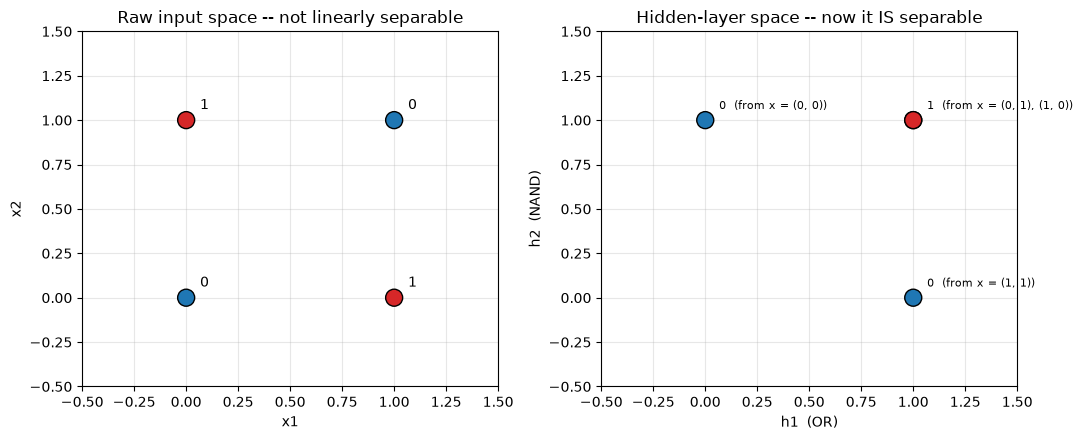

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

colors = np.where(xor_labels == 1, "tab:red", "tab:blue")

ax1.scatter(inputs[:, 0], inputs[:, 1], c=colors, s=150, zorder=3, edgecolor="black")
for (x1, x2), label in zip(inputs, xor_labels):
    ax1.annotate(str(label), (x1, x2), textcoords="offset points", xytext=(10, 8))
ax1.set_xlim(-0.5, 1.5)
ax1.set_ylim(-0.5, 1.5)
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_title("Raw input space -- not linearly separable")

# Two different inputs can land on the same hidden-layer point -- group them
# so we annotate each unique point once, listing every input that maps there.
groups = {}
for x, h, label in zip(inputs, hidden_out, xor_labels):
    key = (round(h[0]), round(h[1]))
    groups.setdefault(key, {"label": label, "sources": []})["sources"].append(tuple(int(v) for v in x))

ax2.scatter(hidden_out[:, 0], hidden_out[:, 1], c=colors, s=150, zorder=3, edgecolor="black")
for (h1, h2), info in groups.items():
    sources = ", ".join(str(s) for s in info["sources"])
    ax2.annotate(
        f"{info['label']}  (from x = {sources})",
        (h1, h2),
        textcoords="offset points",
        xytext=(10, 8),
        fontsize=8,
    )
ax2.set_xlim(-0.5, 1.5)
ax2.set_ylim(-0.5, 1.5)
ax2.set_xlabel("h1  (OR)")
ax2.set_ylabel("h2  (NAND)")
ax2.set_title("Hidden-layer space -- now it IS separable")

plt.tight_layout()
plt.show()

In the raw input space (left), the two classes alternate corners — no
line separates them. But after the hidden layer's transformation (right),
every point that should be labeled 1 lands at $(1, 1)$, and every point
labeled 0 lands at $(0, 1)$ or $(1, 0)$ — a plain **AND** pattern, exactly
the shape a single neuron *can* separate. (Two of the four points land on
top of each other at $(1, 1)$ — that's fine, they agree on the label.)

This is the real trick behind every multi-layer network: **hidden layers
don't solve the problem directly — they re-represent the input into a new
space where the *next* layer's job becomes linearly separable.** The output
layer is still just drawing one straight line, same as Lesson 2 — it's just
drawing it through a space the hidden layer reshaped first.


## 7. Why the hidden layer needs a *nonlinear* activation

It might seem like the hidden layer's activation function is optional
plumbing. It is not — and we can see exactly why with a bit of algebra.
Suppose the hidden layer used the **identity** function (no squashing at
all: $\text{activation}(z) = z$) instead of `step`, `sigmoid`, or `relu`.
Then:

$$ A_1 = Z_1 = X W_1 + b_1 $$
$$ \hat{y} = A_1 W_2 + b_2 = (X W_1 + b_1) W_2 + b_2 = X\underbrace{(W_1 W_2)}_{W_{combined}} + \underbrace{(b_1 W_2 + b_2)}_{b_{combined}} $$

That last expression is *still just $X W_{combined} + b_{combined}$* — a
single weighted sum plus bias, exactly the same shape as one lone neuron's
$z$. **No matter how many neurons the hidden layer has, stacking linear
layers collapses back into one linear layer** — all the extra neurons bought
us nothing. Let's confirm it with numbers, using our XOR weights:


In [8]:
def identity(z):
    return z


W_combined = W1 @ W2
b_combined = b1 @ W2 + b2
print(f"Combined single-layer weights: w = {W_combined.flatten()}, b = {b_combined}")

_, linear_out = forward_pass(inputs, W1, b1, W2, b2, identity)
single_layer_out = inputs @ W_combined + b_combined

print(f"Two 'linear' layers chained : {linear_out.flatten()}")
print(f"One combined linear layer  : {single_layer_out.flatten()}")
print(f"Match: {np.allclose(linear_out, single_layer_out)}")

Combined single-layer weights: w = [0. 0.], b = [-0.5]
Two 'linear' layers chained : [-0.5 -0.5 -0.5 -0.5]
One combined linear layer  : [-0.5 -0.5 -0.5 -0.5]
Match: True


They match exactly — a hidden layer with a linear (or no) activation
is mathematically just one neuron wearing a disguise, with exactly the same
straight-line ceiling as Lesson 3. The hidden layer's activation function
must be **nonlinear** — `step`, `sigmoid`, `relu`, anything with a bend in
it — or the whole network, no matter how many layers or neurons, can never
represent more than a single straight-line boundary.


## 8. One loose end: how would we *train* this?

Everything in this lesson used weights we picked by hand, borrowed straight
from Lesson 2's AND, OR, and NAND gates. That was only possible because we
already knew a logical decomposition of XOR to copy. Real problems don't
come with a decomposition handed to you — the network has to *find* its own
hidden-layer representation from data, the same way Lesson 1 and 3 used
gradient descent to find weights automatically.

Gradient descent still applies here, in principle: the loss is still mean
squared error, and every neuron above still needs a differentiable
activation (Lesson 3's lesson) to have a usable slope. The one new wrinkle is
*whose* slope to compute: the output neuron's error needs to be pushed
*backward* through the output layer's weights to figure out how each hidden
neuron should change too. That backward-flowing chain of slopes is called
**backpropagation**, and it's the subject of the next lesson.


## 9. Recap

- A **multi-layer perceptron (MLP)** chains layers of neurons together: an
  input layer, one or more **hidden layers**, and an output layer. Each
  layer's output becomes the next layer's input.
- The **forward pass** through a layer is the same weighted-sum-plus-bias-
  plus-activation idea from Lessons 2–3, written in matrix form:
  $Z = A_{\text{prev}} W + b$, $A = \text{activation}(Z)$.
- A hidden layer's real job is to **re-represent** the input into a new
  space where the next layer's job becomes linearly separable — not to solve
  the whole problem by itself.
- We hand-designed a 2-neuron hidden layer (OR, NAND) plus an AND output
  neuron that solves **XOR** exactly, by reusing Lesson 2's single-neuron
  gate weights — no training required.
- A hidden layer's activation function **must be nonlinear**. A linear (or
  missing) activation collapses any number of stacked layers back into one
  linear layer, with the exact same straight-line ceiling as a single
  neuron.
- Hand-picking weights only worked because we knew XOR's logical
  decomposition in advance. Training a hidden layer's weights from data
  needs **backpropagation** — next lesson.


## 10. Your turn — exercises

1. **A different decomposition.** XOR can also be written as
   $\text{NOR}(\text{AND}(x_1, x_2), \text{NOR}(x_1, x_2))$. Work out weights
   for this alternative hidden layer (AND, NOR) and output neuron (NOR), and
   confirm it also gets all four XOR cases right.
2. **By hand.** Pick one input row, say $(1, 0)$, and compute $Z_1$, $A_1$,
   $Z_2$, and $\hat{y}$ by hand using `W1`, `b1`, `W2`, `b2` above. Check your
   answer against `forward_pass`.
3. **Smooth it out.** Replace `step` with `sigmoid` in the XOR network above
   (same `W1`, `b1`, `W2`, `b2`). Do all four outputs still land close to the
   right label? If not, try scaling `W1`, `b1`, `W2`, `b2` all up by the same
   large factor (e.g. `x10`) before checking again — what does that do to
   sigmoid's input, and why does it help?
4. **Kill the nonlinearity, on purpose.** Section 7 showed identity
   activations collapse two layers into one. Now try `relu` as the *output*
   layer's activation while keeping `step` on the hidden layer (or vice
   versa) — does the XOR network still get every case right? Which layer's
   nonlinearity actually mattered here?
5. **How many parameters?** For a network with 2 inputs, $H$ hidden neurons,
   and 1 output neuron, write a formula for the total number of weights plus
   biases. Check it against `W1`, `b1`, `W2`, `b2` above for $H = 2$.


In [9]:
# Space for your experiments
